# FXA logS vs logD

In [1]:
import pandas as pd
from mol_faith.notebooks.results_analysis.shared import (
    REAL_WORLD_RESULTS,
    compute_correlation_summary,
    load_raw_data,
    map_explanation_method_names,
    pair_xai_methods,
    plot_correlation_heatmap,
    plot_correlation_scatter_grid,
    process_fidelity_df,
)
from rdkit import Chem, RDLogger
from rdkit.Chem.Scaffolds import MurckoScaffold

RDLogger.DisableLog('rdApp.*')

In [2]:
XAI_METHODS = ['integrated_gradients', 'shap_sampling']
OUTPUT_DIR = REAL_WORLD_RESULTS / 'result_plots' / 'compare_logd_logs'

## Load logS and logD faithfulness results

In [3]:
logs_df, logd_df = (process_fidelity_df(load_raw_data(REAL_WORLD_RESULTS / folder, target_name))
                    for folder, target_name in (('FXa_logs', 'logs'), ('FXa_logd', 'logd')))
logs_df, logd_df = (df[df['explanation_method'].isin(XAI_METHODS)] for df in (logs_df, logd_df))

logs: 16,891 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.2]
14,391 rows | {'faithful': 9537, 'unfaithful': 4854} | normalized_fid in [-1.000, 1.000]


logd: 17,496 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.2]
14,996 rows | {'faithful': 10227, 'unfaithful': 4769} | normalized_fid in [-1.000, 1.000]


## Pair logS/logD Normalized Fid+ per molecule

Merge on `model`, `explanation_method`, `smiles` and `data_split_idx`: the same test molecule appears in both tasks within a fold, so this pairs each molecule's logS Normalized Fid+ with its logD Normalized Fid+ for the same model and xAI method.

In [4]:
merged_df = logs_df.merge(logd_df, on=['model', 'explanation_method', 'smiles', 'data_split_idx'],
                          suffixes=('_logs', '_logd'))
print(f'Paired rows: {len(merged_df):,}')
merged_df.groupby(['model', 'explanation_method']).size()

Paired rows: 5,000


model        explanation_method  
CNN          integrated_gradients    500
             shap_sampling           500
GAT          integrated_gradients    500
             shap_sampling           500
GCN          integrated_gradients    500
             shap_sampling           500
GIN          integrated_gradients    500
             shap_sampling           500
Transformer  integrated_gradients    500
             shap_sampling           500
dtype: int64

## Correlation per model and xAI method

In [5]:
corr_df = compute_correlation_summary(merged_df, ['explanation_method', 'model'],
                                      'normalized_fid_logs', 'normalized_fid_logd')
corr_df

,explanation_method,model,n,pearson_r,pearson_p,spearman_r,spearman_p
0,integrated_gradients,CNN,500,0.155357,4.896167e-04,0.174936,8.415005e-05
1,integrated_gradients,GAT,500,0.335412,1.302346e-14,0.176571,7.199413e-05
2,integrated_gradients,GCN,500,0.224258,4.047945e-07,0.159234,3.508847e-04
3,integrated_gradients,GIN,500,0.138742,1.873137e-03,0.162743,2.578622e-04
4,integrated_gradients,Transformer,500,0.087023,5.180887e-02,0.086707,5.266983e-02
5,shap_sampling,CNN,500,0.163295,2.455172e-04,0.184831,3.203565e-05
6,shap_sampling,GAT,500,0.263628,2.145917e-09,0.172041,1.105459e-04
7,shap_sampling,GCN,500,0.316971,3.930329e-13,0.253692,8.772573e-09
8,shap_sampling,GIN,500,0.196820,9.273901e-06,0.182618,3.993661e-05
9,shap_sampling,Transformer,500,0.138831,1.860401e-03,0.153712,5.626068e-04


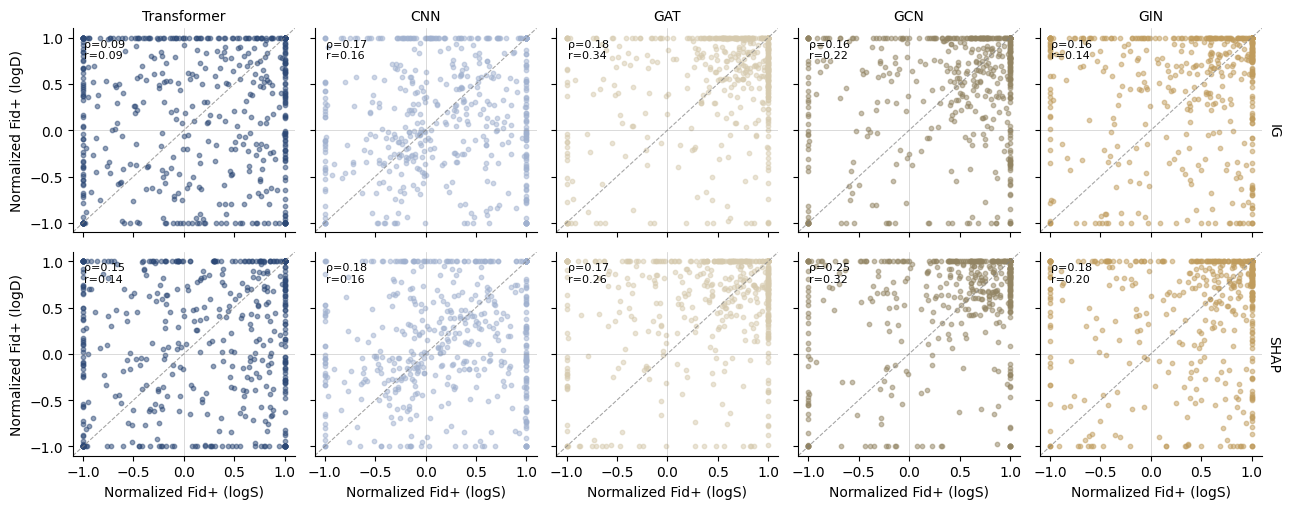

In [6]:
plot_correlation_scatter_grid(map_explanation_method_names(merged_df), map_explanation_method_names(corr_df),
                              row='explanation_method', x='normalized_fid_logs', y='normalized_fid_logd',
                              xlabel='Normalized Fid+ (logS)', ylabel='Normalized Fid+ (logD)',
                              output_dir=OUTPUT_DIR, filename='logs_vs_logd_scatter_grid');

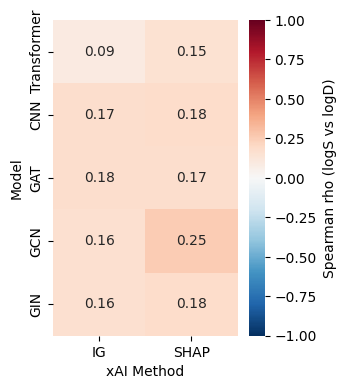

In [7]:
plot_correlation_heatmap(map_explanation_method_names(corr_df), columns='explanation_method',
                         cbar_label='Spearman rho (logS vs logD)', xlabel='xAI Method', figsize=(3.5, 4),
                         output_dir=OUTPUT_DIR, filename='logs_vs_logd_correlation_heatmap');

## IG vs SHAP agreement within each task

Pair the two xAI methods against each other within the same task and model. This tests whether "hard to explain" molecules are intrinsic to the molecule/model regardless of the xAI method, or largely an artifact of the explanation technique.

In [8]:
TASK_ORDER = ['logS', 'logD']
ig_shap_df = pd.concat([pair_xai_methods(logs_df), pair_xai_methods(logd_df)], ignore_index=True)
ig_shap_df['task'] = ig_shap_df['target_name'].map({'logs': 'logS', 'logd': 'logD'})
ig_shap_corr_df = compute_correlation_summary(ig_shap_df, ['task', 'model'], 'normalized_fid_ig', 'normalized_fid_shap')
ig_shap_corr_df

,task,model,n,pearson_r,pearson_p,spearman_r,spearman_p
0,logD,CNN,500,0.665487,2.961317e-65,0.679204,6.635953e-69
1,logD,GAT,500,0.830931,6.708975e-129,0.902649,1.795043e-184
2,logD,GCN,500,0.475736,1.330432e-29,0.591103,1.970903e-48
3,logD,GIN,500,0.650454,1.797407e-61,0.751431,5.595205e-92
4,logD,Transformer,500,0.748529,6.689812e-91,0.766629,7.092116e-98
5,logS,CNN,500,0.746798,2.890410e-90,0.768847,8.961254e-99
6,logS,GAT,500,0.732426,3.516001e-85,0.800099,1.322094e-112
7,logS,GCN,500,0.641944,2.006447e-59,0.699758,9.207459e-75
8,logS,GIN,500,0.548529,1.272381e-40,0.640767,3.807443e-59
9,logS,Transformer,500,0.714466,2.851794e-79,0.755649,1.428099e-93


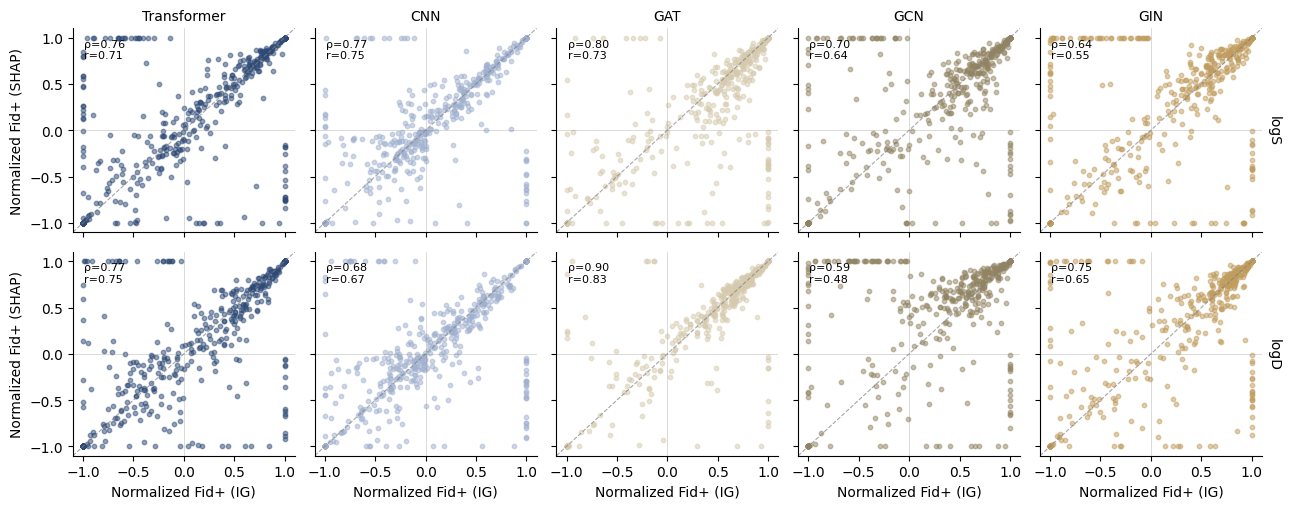

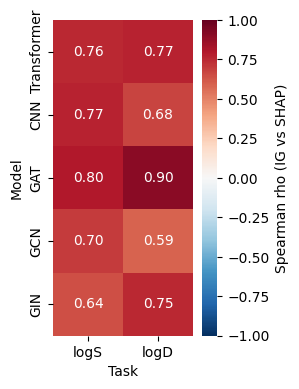

In [9]:
plot_correlation_scatter_grid(ig_shap_df, ig_shap_corr_df, row='task', x='normalized_fid_ig', y='normalized_fid_shap',
                              xlabel='Normalized Fid+ (IG)', ylabel='Normalized Fid+ (SHAP)', row_order=TASK_ORDER,
                              output_dir=OUTPUT_DIR, filename='ig_vs_shap_scatter_grid')
plot_correlation_heatmap(ig_shap_corr_df, column_order=TASK_ORDER, output_dir=OUTPUT_DIR);

## Scaffold-level logS vs logD correlation

Average `normalized_fid` per Murcko scaffold (model + method + scaffold) to cancel per-molecule noise, keeping only scaffolds with >= 3 test molecules, then rerun the logS/logD correlation on scaffold means. A stronger correlation than at the per-molecule level would point to substructures that are intrinsically hard to explain in both tasks.

In [10]:
MIN_SCAFFOLD_SIZE = 3


def get_scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return Chem.MolToSmiles(MurckoScaffold.GetScaffoldForMol(mol)) if mol else None


merged_df['scaffold'] = merged_df['smiles'].map({s: get_scaffold(s) for s in merged_df['smiles'].unique()})
scaffold_df = (
    merged_df.groupby(['model', 'explanation_method', 'scaffold'])
    .agg(normalized_fid_logs=('normalized_fid_logs', 'mean'),
         normalized_fid_logd=('normalized_fid_logd', 'mean'),
         n_molecules=('smiles', 'nunique'))
    .query('n_molecules >= @MIN_SCAFFOLD_SIZE')
    .reset_index()
)
scaffold_corr_df = compute_correlation_summary(scaffold_df, ['explanation_method', 'model'],
                                               'normalized_fid_logs', 'normalized_fid_logd')
print(f'Scaffold groups (n>={MIN_SCAFFOLD_SIZE}): {len(scaffold_df)}')
scaffold_corr_df

Scaffold groups (n>=3): 210


,explanation_method,model,n,pearson_r,pearson_p,spearman_r,spearman_p
0,integrated_gradients,CNN,21,-0.027719,0.905064,0.041558,0.858048
1,integrated_gradients,GAT,21,0.651548,0.001375,0.612987,0.003131
2,integrated_gradients,GCN,21,0.463093,0.034505,0.166234,0.471422
3,integrated_gradients,GIN,21,0.082757,0.721369,0.124675,0.590261
4,integrated_gradients,Transformer,21,0.011556,0.960350,-0.042857,0.853657
5,shap_sampling,CNN,21,0.180529,0.433571,0.218182,0.342048
6,shap_sampling,GAT,21,0.454798,0.038318,0.541558,0.011226
7,shap_sampling,GCN,21,-0.225043,0.326699,-0.049351,0.831769
8,shap_sampling,GIN,21,0.290700,0.201107,0.309091,0.172768
9,shap_sampling,Transformer,21,-0.001882,0.993540,0.036364,0.875650


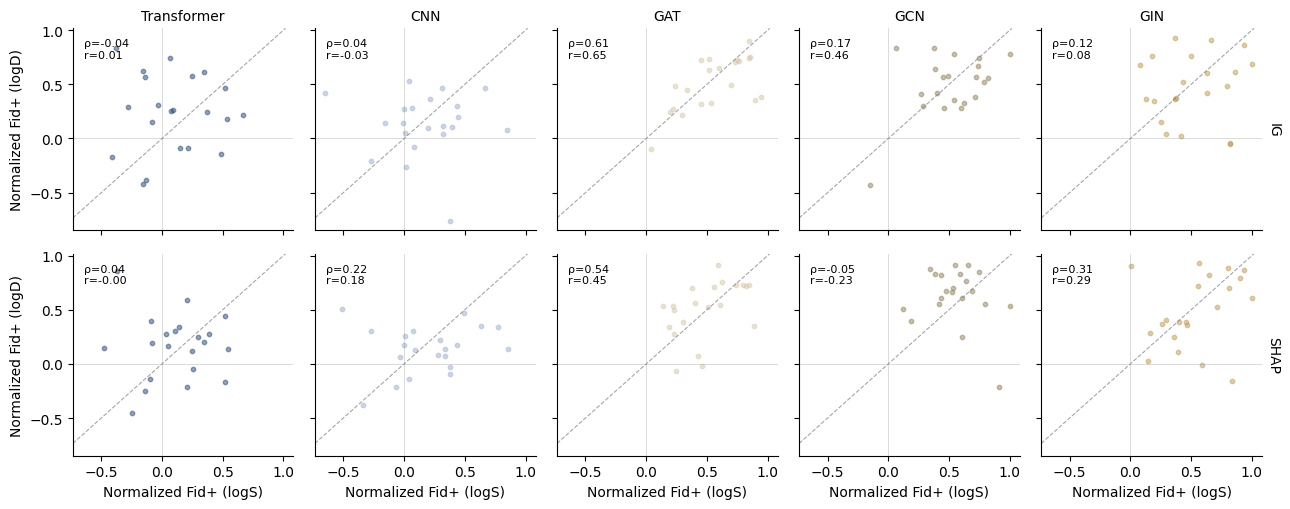

In [11]:
plot_correlation_scatter_grid(map_explanation_method_names(scaffold_df), map_explanation_method_names(scaffold_corr_df),
                              row='explanation_method', x='normalized_fid_logs', y='normalized_fid_logd',
                              xlabel='Normalized Fid+ (logS)', ylabel='Normalized Fid+ (logD)',
                              output_dir=OUTPUT_DIR / 'scaffold_level', filename='logs_vs_logd_scatter_grid');

## TMAP colored by Normalized Fid+

One TMAP tree (via `tmap2`) over the molecules shared by logS and logD for a model + xAI method, with both tasks' `normalized_fid` (averaged over splits) as separate color layers on the same layout.

In [12]:
from tmap import TMAP
from tmap.utils import fingerprints_from_smiles


def plot_tmap_logs_logd(df, model, explanation_method, fp_type='morgan', n_neighbors=20, seed=42, color='RdBu_r',
                        output_dir=None):
    sub = df[(df['model'] == model) & (df['explanation_method'] == explanation_method)]
    agg = sub.groupby('smiles', as_index=False)[['normalized_fid_logs', 'normalized_fid_logd']].mean()
    agg = agg[agg['smiles'].map(lambda s: Chem.MolFromSmiles(s) is not None)].reset_index(drop=True)

    tm = TMAP(metric='jaccard', n_neighbors=n_neighbors, seed=seed).fit(
        fingerprints_from_smiles(agg['smiles'].tolist(), fp_type=fp_type))
    viz = tm.to_tmapviz()
    viz.title = f'{model} / {explanation_method}'
    viz.add_smiles(agg['smiles'].tolist())
    viz.add_color_layout('Normalized Fid+ (logS)', agg['normalized_fid_logs'].tolist(), color=color)
    viz.add_color_layout('Normalized Fid+ (logD)', agg['normalized_fid_logd'].tolist(), color=color)

    html_path = None
    if output_dir:
        output_dir.mkdir(parents=True, exist_ok=True)
        html_path = viz.write_html(output_dir / f'tmap_{model}_{explanation_method}_logs_logd.html'.lower())
    return viz, agg, html_path

In [13]:
viz, tmap_data, html_path = plot_tmap_logs_logd(merged_df, model='GAT', explanation_method='shap_sampling',
                                                output_dir=OUTPUT_DIR / 'tmap')
html_path

PosixPath('/home/marcelhiltscher/Documents/Projects/MolFaith/results/real_world/result_plots/compare_logd_logs/tmap/tmap_gat_shap_sampling_logs_logd.html')